Цель задания: спроектировать и реализовать объектную модель учёта банковских операций с опорой на материалы тем 1–5 (файлы, datetime, pandas, регулярные выражения, ООП).

Контекст: нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

Решение оформляется в объектно-ориентированном стиле. Структуру классов, имена методов и способ хранения данных можно выбирать самостоятельно; важно соблюсти правила и подтвердить работу демонстрацией в ноутбуке.

Для сдачи нужно прикрепить в LMS ссылку на выполненное задание в Google Colab или GitHub и убедиться, что по ссылке есть доступ.

Задание 1.

Этап 1. Правила

Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным; по умолчанию он равен 0.

Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX — порядковый номер. Счётчик начинается с 1000, номера должны быть уникальными.

Поддерживаются пополнение и снятие. Сумма операции должна быть положительной; некорректная сумма приводит к исключению.

При успешной операции баланс обновляется, а в историю добавляется запись со статусом success.

Если средств недостаточно, баланс не меняется, но попытка фиксируется в истории со статусом fail.

Каждая запись истории содержит минимум тип операции (deposit / withdraw), сумму, дату и время, баланс после операции и статус (success / fail). Для времени используется модуль datetime.

Должна быть возможность узнать текущий баланс и получить историю в удобном для чтения виде.

Показать в ноутбуке: создание счёта, несколько успешных пополнений и снятий, хотя бы одно неуспешное снятие, вывод баланса и истории.

In [1]:
# Общие правила для двух типов счетов.
import csv
import json
import re
from datetime import datetime
from decimal import Decimal, InvalidOperation
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import pandas as pd


# Переводим сумму в Decimal для точного расчёта денег.
def to_decimal(value):
    if isinstance(value, bool) or value is None or str(value).strip() == "":
        raise ValueError("Сумма должна быть числом")
    try:
        result = Decimal(str(value))
    except InvalidOperation as error:
        raise ValueError("Сумма должна быть числом") from error
    if not result.is_finite():
        raise ValueError("Сумма должна быть конечным числом")
    return result


# Здесь лежат общие правила для всех счетов.
class BankAccount:

    _next_number = 1000
    account_type = None
    _name_pattern = re.compile(
        r"(?:[А-ЯЁ][а-яё]*|[A-Z][a-z]*) (?:[А-ЯЁ][а-яё]*|[A-Z][a-z]*)"
    )

    # Проверяем владельца и создаём новый счёт.
    def __init__(self, owner, initial_balance=0):
        valid_owner = (
            isinstance(owner, str)
            and self._name_pattern.fullmatch(owner)
        )
        if not valid_owner:
            raise ValueError("Имя владельца должно иметь формат «Имя Фамилия»")
        balance = to_decimal(initial_balance)
        if balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным")
        if self.account_type is None:
            raise TypeError("Создайте расчётный или сберегательный счёт")
        self.owner = owner
        self._balance = balance
        self.number = f"ACC-{BankAccount._next_number:04d}"
        BankAccount._next_number += 1
        self.history = []

    def __repr__(self):
        return (f"{self.__class__.__name__}(number={self.number!r}, "
                f"owner={self.owner!r}, balance={self.balance})")

    # Баланс можно прочитать но нельзя изменить напрямую.
    @property
    def balance(self):
        return self._balance

    def __str__(self):
        return (f"Счёт {self.number} ({self.account_type}), "
                f"владелец: {self.owner}, баланс: {self.balance}")

    # Проверяем что сумма больше нуля.
    @staticmethod
    def _positive_amount(value):
        amount = to_decimal(value)
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной")
        return amount

    # Проверяем хватает ли денег для снятия.
    def _withdrawal_error(self, amount):
        if amount > self.balance:
            return "Недостаточно средств"
        return None

    # Записываем результат операции в историю.
    def _record(self, operation, amount, status, date=None, transfer_id=None):
        entry = {
            "operation": operation,
            "amount": amount,
            "date": date or datetime.now(),
            "balance_after": self.balance,
            "status": status,
            "transfer_id": transfer_id,
        }
        self.history.append(entry)
        return entry

    def deposit(self, amount, transfer_id=None):
        amount = self._positive_amount(amount)
        self._balance += amount
        self._record("deposit", amount, "success", transfer_id=transfer_id)
        return self.balance

    # При отказе сохраняем попытку и не меняем баланс.
    def withdraw(self, amount, transfer_id=None):
        amount = self._positive_amount(amount)
        if self._withdrawal_error(amount):
            self._record("withdraw", amount, "fail", transfer_id=transfer_id)
            return False
        self._balance -= amount
        self._record("withdraw", amount, "success", transfer_id=transfer_id)
        return True

    # Переводим деньги только после успешного снятия.
    def transfer_to(self, recipient, amount):
        if not isinstance(recipient, BankAccount) or recipient is self:
            raise ValueError("Получатель должен быть другим банковским счётом")
        amount = self._positive_amount(amount)
        transfer_id = uuid4().hex
        if not self.withdraw(amount, transfer_id=transfer_id):
            return False
        recipient.deposit(amount, transfer_id=transfer_id)
        return True

    # Возвращаем копию истории.
    def get_history(self):
        return [entry.copy() for entry in self.history]

    # Ищем последние крупные успешные операции.
    def large_operations(self, threshold, n):
        threshold = self._positive_amount(threshold)
        if not isinstance(n, int) or isinstance(n, bool) or n < 0:
            raise ValueError("N должно быть неотрицательным целым числом")
        matches = [entry.copy() for entry in self.history
                   if entry["status"] == "success"
                   and entry["amount"] >= threshold]
        return matches[-n:][::-1] if n else []

    # Читаем файл и берём операции нужного счёта.
    def load_history(self, path, source_account_number):
        path = Path(path)
        if path.suffix.lower() == ".csv":
            with path.open(encoding="utf-8-sig", newline="") as file:
                rows = list(csv.DictReader(file))
        elif path.suffix.lower() == ".json":
            with path.open(encoding="utf-8-sig") as file:
                rows = json.load(file)
        else:
            raise ValueError("Поддерживаются только CSV и JSON")
        if not isinstance(rows, list):
            raise ValueError("Ожидается список операций")

        report = {"accepted": 0, "rejected": 0, "filtered": 0,
                  "reasons": []}
        allowed = {"deposit", "withdraw"}
        if self.account_type == "savings":
            allowed.add("interest")
        for line_number, row in enumerate(rows, start=1):
            if not isinstance(row, dict):
                report["rejected"] += 1
                report["reasons"].append(
                    (line_number, "Строка не является объектом")
                )
                continue
            if row.get("account_number") != source_account_number:
                report["filtered"] += 1
                continue
            try:
                if row.get("account_type") != self.account_type:
                    raise ValueError("Неверный тип счёта")
                operation = row.get("operation")
                if operation not in allowed:
                    raise ValueError(f"Недопустимая операция: {operation!r}")
                amount = self._positive_amount(row.get("amount"))
                date = datetime.strptime(row.get("date", ""),
                                         "%Y-%m-%d %H:%M:%S")
                if row.get("status") not in {"success", "fail"}:
                    raise ValueError("Неверный статус")
                # Проверяем поле но баланс считаем заново.
                source_balance = to_decimal(row.get("balance_after"))
                if source_balance < 0:
                    raise ValueError("Отрицательный баланс в файле")
                if row["status"] == "success" and operation == "withdraw":
                    error = self._withdrawal_error(amount)
                    if error:
                        raise ValueError(error)
            except (ValueError, TypeError) as error:
                report["rejected"] += 1
                report["reasons"].append((line_number, str(error)))
                continue

            if row["status"] == "success":
                if operation == "withdraw":
                    self._balance -= amount
                else:
                    self._balance += amount
            self._record(operation, amount, row["status"], date=date)
            report["accepted"] += 1
        return report


# Расчётный счёт работает по общим правилам.
class CheckingAccount(BankAccount):

    account_type = "checking"


# Сберегательный счёт ограничивает снятие.
class DepositAccount(BankAccount):

    account_type = "savings"

    def _withdrawal_error(self, amount):
        error = super()._withdrawal_error(amount)
        if error:
            return error
        if amount > self.balance / 2:
            return "Нельзя снять больше 50% текущего баланса"
        return None

    # Начисляем проценты на текущий баланс.
    def accrue_interest(self, rate):
        rate = self._positive_amount(rate)
        amount = (self.balance * rate / 100).quantize(Decimal("0.01"))
        if amount <= 0:
            raise ValueError("Начисленные проценты должны быть положительными")
        self._balance += amount
        self._record("interest", amount, "success")
        return amount


In [2]:
checking = CheckingAccount("Миша Кальдебаран", 1000)

checking.deposit(250)
checking.deposit(100)
checking.withdraw(200)
checking.withdraw(50)
checking.withdraw(2000)  # Недостаточно средств. Запись fail.

print(checking)
print("Текущий баланс:", checking.balance)
display(pd.DataFrame(checking.get_history()))

assert checking.balance == Decimal("1100")
assert checking.history[-1]["status"] == "fail"
assert checking.history[-1]["balance_after"] == checking.balance


Счёт ACC-1000 (checking), владелец: Миша Кальдебаран, баланс: 1100
Текущий баланс: 1100


,operation,amount,date,balance_after,status,transfer_id
0,deposit,250,2026-10-23 23:53:06.845600,1250,success,None
1,deposit,100,2026-10-23 23:53:06.845610,1350,success,None
2,withdraw,200,2026-10-23 23:53:06.845618,1150,success,None
3,withdraw,50,2026-10-23 23:53:06.845624,1100,success,None
4,withdraw,2000,2026-10-23 23:53:06.845631,1100,fail,None


Этап 2.

По истории операций построить линейный график изменения баланса во времени: ось X — время операции, ось Y — баланс после операции. У графика должны быть заголовок и подписи осей. Данные для графика берутся из истории через pandas.

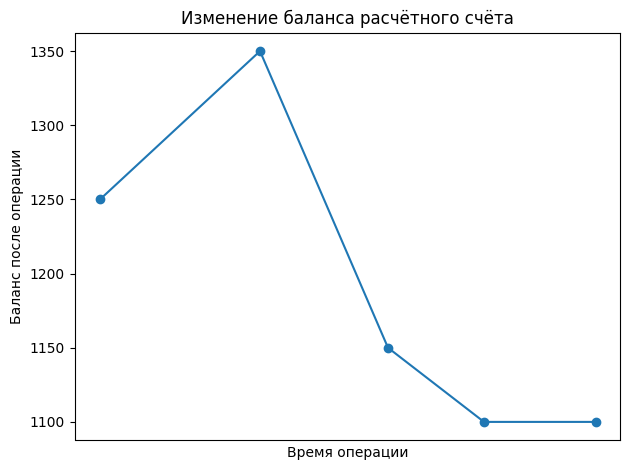

In [3]:
# График изменения баланса.
plot_data = pd.DataFrame(checking.get_history())
plot_data["date"] = pd.to_datetime(plot_data["date"])
plot_data["balance_after"] = plot_data["balance_after"].astype(float)
ax = plot_data.plot(x="date", y="balance_after", marker="o", legend=False)
ax.set_title("Изменение баланса расчётного счёта")
ax.set_xlabel("Время операции")
ax.set_ylabel("Баланс после операции")
plt.tight_layout()
plt.show()


Задание 2. Разные типы счетов и аналитика

Расчётный и сберегательный счета имеют общую логику учёта операций, но отличаются правилами.

Расчётный счёт поддерживает базовые пополнение и снятие без ограничения на долю снимаемой суммы.

Сберегательный счёт умеет начислять проценты на текущий остаток по ставке, заданной вызывающим кодом (например, 7%). С него нельзя снять больше 50% текущего баланса. Такая попытка не меняет баланс и фиксируется в истории как неуспешная.

Тип каждого счёта должен быть различим по объекту или его данным.

Имя владельца проверяется регулярным выражением: формат «Имя Фамилия», оба слова с заглавной буквы, кириллица или латиница. Иначе возникает исключение.

По истории можно получить последние N крупных успешных операций; порог крупности и N задаёт вызывающий код.

Показать в ноутбуке: создание расчётного и сберегательного счетов, начисление процентов, отклонение снятия сверх 50%, выборку последних крупных операций и реакцию на некорректное имя и/или сумму.

In [4]:
deposit_account = DepositAccount("Ани Лорак", 1000)

print("Начисленные проценты (7%):", deposit_account.accrue_interest(7))
print("Снятие 600:", deposit_account.withdraw(600))  # Больше половины баланса.
print("Снятие 500:", deposit_account.withdraw(500))
print("Сберегательный счёт:", deposit_account)

display(pd.DataFrame(deposit_account.get_history()))

assert deposit_account.balance == Decimal("570.00")
assert deposit_account.history[1]["status"] == "fail"

print("Последние две крупные успешные операции от 200:")
display(pd.DataFrame(deposit_account.large_operations(200, 2)))

for action in (
    lambda: CheckingAccount("миша Кальдебаран"),
    lambda: checking.deposit(-10),
    lambda: deposit_account.withdraw(0),

):
    try:
        action()
    except ValueError as error:
        print("Ожидаемая ошибка:", error)


Начисленные проценты (7%): 70.00
Снятие 600: False
Снятие 500: True
Сберегательный счёт: Счёт ACC-1001 (savings), владелец: Ани Лорак, баланс: 570.00


,operation,amount,date,balance_after,status,transfer_id
0,interest,70.00,2026-10-23 23:53:06.903406,1070.00,success,None
1,withdraw,600,2026-10-23 23:53:06.903506,1070.00,fail,None
2,withdraw,500,2026-10-23 23:53:06.903521,570.00,success,None


Последние две крупные успешные операции от 200:


,operation,amount,date,balance_after,status,transfer_id
0,withdraw,500,2026-10-23 23:53:06.903521,570.00,success,None


Ожидаемая ошибка: Имя владельца должно иметь формат «Имя Фамилия»
Ожидаемая ошибка: Сумма операции должна быть положительной
Ожидаемая ошибка: Сумма операции должна быть положительной


Доп задание

In [5]:
# Перевод между счетами.
recipient = CheckingAccount("Ivan Kuznetsov", 100)
print("Перевод 100:", deposit_account.transfer_to(recipient, 100))
recipient_before = recipient.balance
print("Перевод 300:", deposit_account.transfer_to(recipient, 300))
print("Отправитель:", deposit_account.balance,
      "Получатель:", recipient.balance)
display(pd.DataFrame(deposit_account.get_history()).tail(2))
display(pd.DataFrame(recipient.get_history()).tail(1))

assert recipient.balance == recipient_before
assert (
    deposit_account.history[-2]["transfer_id"]
    == recipient.history[-1]["transfer_id"]
)
assert deposit_account.history[-1]["status"] == "fail"


Перевод 100: True
Перевод 300: False
Отправитель: 470.00 Получатель: 200


,operation,amount,date,balance_after,status,transfer_id
3,withdraw,100,2026-10-23 23:53:06.910250,470.00,success,c34aa5ab4ab749c796ea460b0880862e
4,withdraw,300,2026-10-23 23:53:06.910335,470.00,fail,3dc243a76e2c497fa1e0f29a7ecd3040


,operation,amount,date,balance_after,status,transfer_id
0,deposit,100,2026-10-23 23:53:06.910253,200,success,c34aa5ab4ab749c796ea460b0880862e


Задание 3. Загрузка «грязных» данных

Использовать файлы transactions_dirty.csv и transactions_dirty.json из личного кабинета. Файлы общие для нескольких счетов, поэтому в конкретный счёт нужно загружать только его операции, отбирая их по номеру и типу счёта.

Реализовать загрузку истории из CSV и/или JSON.

Перед добавлением в историю отбрасывать невалидные строки: опечатки в типе операции, пустые и отрицательные суммы, некорректные даты и статусы и другие ошибки.

Для сберегательного счёта допустимы deposit, withdraw, interest; для расчётного — только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.

После загрузки баланс должен соответствовать последовательности принятых операций.

Показать в ноутбуке: загрузку хотя бы из одного формата в расчётный и сберегательный счёт, обновлённые балансы и фрагменты историй.

Дополнительное задание. Отчёт об отбраковке

Помимо отбрасывания мусора сформировать явный результат очистки: сколько строк принято, сколько отклонено и почему отклонена каждая строка или группа строк. Примеры причин: битая дата, пустая сумма, diposit, interest на расчётном счёте, неверный статус. Формат отчёта можно выбрать самостоятельно, главное — показать по нему, что произошло с данными.

In [6]:
from pathlib import Path

loaded_checking = CheckingAccount("Питер Петер", 1200)
checking_report = loaded_checking.load_history(
    Path("transactions_dirty.csv"), "ACC-100001"
)
loaded_deposit = DepositAccount("Мария Макароны", 1500)
deposit_report = loaded_deposit.load_history(
    Path("transactions_dirty.json"), "ACC-100002"
)

for title, account, report in (
    ("Расчётный CSV", loaded_checking, checking_report),
    ("Сберегательный JSON", loaded_deposit, deposit_report),
):
    print("\n", title, "->", account)
    print("Принято:", report["accepted"],
          "отклонено:", report["rejected"],
          "другие счета:", report["filtered"])
    display(pd.DataFrame(report["reasons"],
                         columns=["Строка", "Причина отклонения"]))
    display(pd.DataFrame(account.get_history()).tail(5))

assert checking_report["accepted"] == len(loaded_checking.history)
assert deposit_report["accepted"] == len(loaded_deposit.history)
report_keys = ("accepted", "rejected", "filtered")
assert sum(checking_report[key] for key in report_keys) == 105
assert sum(deposit_report[key] for key in report_keys) == 105



 Расчётный CSV -> Счёт ACC-1003 (checking), владелец: Питер Петер, баланс: 4540.0
Принято: 16 отклонено: 10 другие счета: 79


,Строка,Причина отклонения
0,4,time data '28/09/2025 22:17' does not match fo...
1,6,Сумма должна быть числом
2,9,Недопустимая операция: ''
3,11,Недопустимая операция: 'interest'
4,14,time data '2025-17-34 12:00:00' does not match...
5,15,time data '06/10/2025 22:17' does not match fo...
6,16,Недопустимая операция: 'diposit'
7,17,Недопустимая операция: 'interest'
8,18,time data '2023-16-40 12:00:00' does not match...
9,25,Неверный статус


,operation,amount,date,balance_after,status,transfer_id
11,withdraw,393.0,2025-10-16 22:17:26,4405.0,success,None
12,deposit,701.0,2025-10-16 22:17:26,5106.0,success,None
13,withdraw,308.0,2025-10-17 22:17:26,4798.0,success,None
14,deposit,135.0,2025-10-18 22:17:26,4933.0,success,None
15,withdraw,393.0,2025-10-16 22:17:26,4540.0,success,None



 Сберегательный JSON -> Счёт ACC-1004 (savings), владелец: Мария Макароны, баланс: 3169.96
Принято: 16 отклонено: 11 другие счета: 78


,Строка,Причина отклонения
0,29,time data '2023-22-32 12:00:00' does not match...
1,30,Сумма должна быть числом
2,32,time data '04/10/2025 22:17' does not match fo...
3,34,Сумма операции должна быть положительной
4,36,time data '09/10/2025 22:17' does not match fo...
5,38,Недопустимая операция: 'diposit'
6,45,Сумма операции должна быть положительной
7,47,Неверный статус
8,49,Недопустимая операция: 'wdraw'
9,101,time data '09/10/2025 22:17' does not match fo...


,operation,amount,date,balance_after,status,transfer_id
11,withdraw,231.0,2025-10-14 22:17:26,3161.70,success,None
12,interest,274.13,2025-10-15 22:17:26,3435.83,success,None
13,withdraw,286.0,2025-10-17 22:17:26,3149.83,success,None
14,interest,302.13,2025-10-20 22:17:26,3451.96,success,None
15,withdraw,282.0,2025-10-23 22:17:26,3169.96,success,None
